In [1]:
import random, time
import numpy as np
import torch , torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
SEED = 42
BATCH_SIZE = 32
IMG_SIZE = 224
VAL_FRAC = 0.2
EPOCHS_HEAD, EPOCHS_FT = 3, 7
LR_HEAD, LR_FT = 1e-3, 1e-4

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(device)

cpu


In [3]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

In [5]:
full_train_aug  = datasets.OxfordIIITPet("data", split="trainval", target_types="category", transform=train_tf, download=True)
full_train_eval = datasets.OxfordIIITPet("data", split="trainval", target_types="category", transform=eval_tf)
test_ds         = datasets.OxfordIIITPet("data", split="test",     target_types="category", transform=eval_tf)

class_names = full_train_aug.classes
n = len(full_train_aug)
idx = torch.randperm(n, generator=torch.Generator().manual_seed(SEED)).tolist()
n_val = int(n * VAL_FRAC)
val_idx, train_idx = idx[:n_val], idx[n_val:]

train_ds = Subset(full_train_aug, train_idx)   # augmented
val_ds   = Subset(full_train_eval, val_idx)    # not augmented

print(len(train_ds), len(val_ds), len(test_ds), len(class_names))

2944 736 3669 37


In [6]:
train_dl = DataLoader(train_ds, BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

d:\ali\Programming\oxford-IIIT-pet-classification\.venv\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


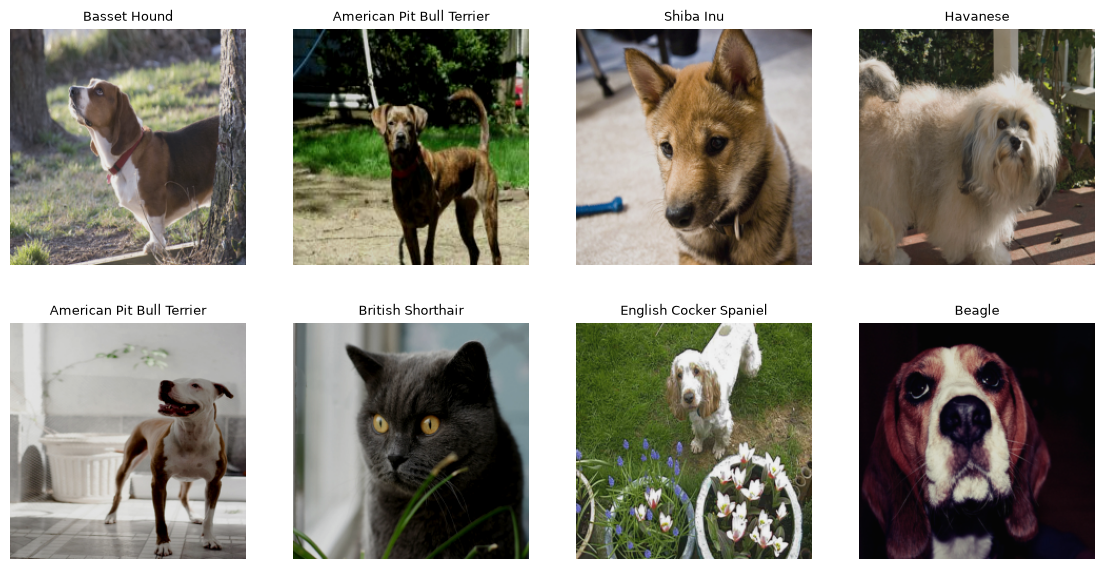

In [7]:
def show_batch(dl, n=8):
    x, y = next(iter(dl))
    x = x[:n] * torch.tensor(std).view(1,3,1,1) + torch.tensor(mean).view(1,3,1,1)
    fig, axs = plt.subplots(2, n//2, figsize=(14, 7))
    for ax, img, lab in zip(axs.flat, x, y[:n]):
        ax.imshow(img.permute(1,2,0).clamp(0,1)); ax.set_title(class_names[lab], fontsize=9); ax.axis("off")
    plt.show()

show_batch(train_dl)

In [8]:
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
for p in model.parameters():
    p.requires_grad = False                       # freeze backbone
model.fc = nn.Linear(model.fc.in_features, len(class_names))  # new head (trainable)
model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\HP/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100.0%


In [9]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

def make_optimizer(lr):
    params = [p for p in model.parameters() if p.requires_grad]
    return torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)

def run_epoch(dl, optimizer=None, scheduler=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, total = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
                if scheduler: scheduler.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total

In [10]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val, best_state = 0, None

def fit(epochs, lr, use_cosine=False):
    global best_val, best_state
    opt = make_optimizer(lr)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs*len(train_dl)) if use_cosine else None
    for ep in range(epochs):
        t0 = time.time()
        tl, ta = run_epoch(train_dl, opt, sched)
        vl, va = run_epoch(val_dl)
        for k, v in zip(history, (tl, ta, vl, va)): history[k].append(v)
        if va > best_val:
            best_val = va
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"ep {ep+1}/{epochs} | train {tl:.3f}/{ta:.3f} | val {vl:.3f}/{va:.3f} | {time.time()-t0:.0f}s")

fit(EPOCHS_HEAD, LR_HEAD)

ep 1/3 | train 2.292/0.649 | val 1.488/0.879 | 1163s
ep 2/3 | train 1.200/0.913 | val 1.113/0.917 | 1146s
ep 3/3 | train 1.006/0.939 | val 1.030/0.914 | 1159s


In [1]:
for p in model.parameters():
    p.requires_grad = True

fit(EPOCHS_FT, LR_FT, use_cosine=True)

NameError: name 'model' is not defined

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["train_acc"],  label="train"); ax[1].plot(history["val_acc"],  label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
for a in ax: a.axvline(EPOCHS_HEAD - 0.5, ls="--", c="gray")   # phase boundary
plt.show()

In [ ]:
model.load_state_dict(best_state)
model.to(device)
test_loss, test_acc = run_epoch(test_dl)
print(f"Test accuracy: {test_acc:.4f}")

In [ ]:
model.eval()
preds, labels = [], []
with torch.no_grad():
    for x, y in test_dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist()
        labels += y.tolist()

print(classification_report(labels, preds, target_names=class_names, digits=3))

cm = confusion_matrix(labels, preds)
np.fill_diagonal(cm, 0)
pairs = sorted(((cm[i, j], class_names[i], class_names[j]) for i in range(37) for j in range(37) if cm[i, j]), reverse=True)[:8]
for c, true, pred in pairs: print(f"{c:2d}x  {true}  ->  {pred}")

In [ ]:
torch.save({"state_dict": best_state, "classes": class_names}, "pets_resnet50.pt")

from PIL import Image
def predict(path, k=3):
    img = eval_tf(Image.open(path).convert("RGB")).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probs = model(img).softmax(1)[0]
    top = probs.topk(k)
    return [(class_names[i], round(p.item(), 3)) for p, i in zip(top.values, top.indices)]

# predict("my_pet.jpg")